# 04 · Data quality

Rule I follow: **never silently delete a record.** Every check either

- **excludes** a row from analysis (`include_in_analysis = 0`) — e.g. duplicates, non-India locations, missing price — or
- **flags** it and keeps it — e.g. pack size guessed from the name.

Each fired check is written to `dq_issue_log`, and `dq_check_summary` counts them per run.

In [1]:
import sys, sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 45)

from config import DB_PATH
import viz

con = sqlite3.connect(DB_PATH)
summary = pd.read_sql("""SELECT check_name, source_code, rows_checked, rows_flagged, action, description
                         FROM dq_check_summary
                         WHERE run_id = (SELECT MAX(run_id) FROM dq_check_summary) AND rows_flagged > 0
                         ORDER BY rows_flagged DESC""", con)
summary

,check_name,source_code,rows_checked,rows_flagged,action,description
0,missing_pack_size,OPEN_PRICES,402,78,flag only,Pack size/unit unknown -> normalised pric...
1,brand_alias_mapped,OPEN_PRICES,402,43,flag only,Brand spelling standardised via alias table
2,missing_brand,OPEN_PRICES,402,32,flag only,Brand missing in source
3,unclassified_category,OPEN_PRICES,402,24,flag only,No category tags in source
4,missing_product_name,OPEN_PRICES,402,18,flag only,Product name missing in source
5,out_of_scope_location,OPEN_PRICES,402,12,exclude from analysis,Observation located outside India / no co...
6,changed_product_name,DOCA_PMD,275,7,flag only,Same barcode/commodity seen with more tha...
7,exact_duplicate,OPEN_PRICES,402,7,exclude from analysis,"Same product, outlet, date and price alre..."
8,not_reported_by_source,DOCA_PMD,275,7,exclude from analysis,DoCA shows '--' for this commodity/date (...
9,pack_size_from_name,OPEN_PRICES,402,7,flag only,Pack size parsed from product name/quanti...


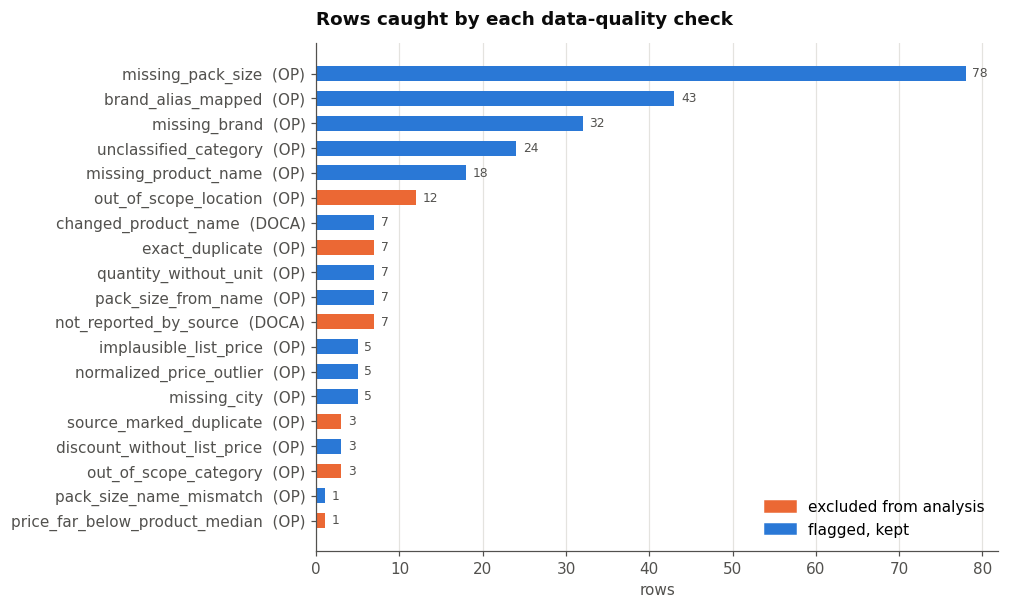

In [2]:
s = summary.sort_values("rows_flagged")
fig, ax = plt.subplots(figsize=(8, 6))
colors = [viz.ORANGE if a == "exclude from analysis" else viz.BLUE for a in s["action"]]
ax.barh(s["check_name"] + "  (" + s["source_code"].str.replace("_PMD", "").str.replace("OPEN_PRICES", "OP") + ")",
        s["rows_flagged"], color=colors, height=0.6)
for y, v in enumerate(s["rows_flagged"]):
    ax.text(v + 0.8, y, str(v), va="center", fontsize=8, color=viz.MUTED)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=viz.ORANGE, label="excluded from analysis"),
                   Patch(color=viz.BLUE, label="flagged, kept")], frameon=False, loc="lower right")
viz.style(ax, "Rows caught by each data-quality check", xlabel="rows")
viz.save(fig, "04_dq_checks"); plt.show()

## How much survives?

In [3]:
pd.read_sql("""SELECT s.source_code,
                      COUNT(*) AS rows_total,
                      SUM(f.include_in_analysis) AS used_in_analysis,
                      SUM(1 - f.include_in_analysis) AS excluded,
                      SUM(f.dq_flags IS NOT NULL) AS carrying_any_flag
               FROM fact_price f JOIN dim_source s USING(source_key)
               GROUP BY s.source_code""", con)

,source_code,rows_total,used_in_analysis,excluded,carrying_any_flag
0,DOCA_PMD,275,268,7,14
1,OPEN_PRICES,402,379,23,152


## Real problems the checks caught

### Duplicate submissions
Crowd-sourced data has people uploading the same receipt twice. The first copy is kept; later copies point to it.

In [4]:
pd.read_sql("""SELECT f.price_id, f.duplicate_of_price_id, p.product_name, f.price_paid, d.full_date, l.city
               FROM fact_price f JOIN dim_product p USING(product_key)
               JOIN dim_date d ON d.date_key=f.date_key JOIN dim_location l ON l.location_key=f.location_key
               WHERE f.is_duplicate = 1""", con)

,price_id,duplicate_of_price_id,product_name,price_paid,full_date,city
0,475,474,PR Golden Tea,10.0,2025-08-24,Lucknow
1,499,498,Surf Excel Matic Front Load Liquid Detergent,160.0,2025-09-27,Madurai
2,554,553,Classmate book,25.0,2025-12-16,Hyderabad
3,639,606,Amul Protein Blueberry Shake,50.0,2026-02-06,Lucknow
4,651,650,Kissan No onion no garlic Tomato Ketchup,130.0,2026-08-09,Surat
5,669,668,Bombay Bunta Masala Soda,20.0,2026-09-13,Bhopal
6,675,674,Vita ghee,705.0,2026-09-26,Kurukshetra


### Impossible "price before discount"
One record claims a milk powder was ₹99,99,999 before discount. Left in, it would have inflated "total savings" from about ₹4,200 to ₹1 crore. These rows stay in the database (their paid price may be fine) but are left out of discount metrics.

In [5]:
pd.read_sql("""SELECT p.product_name, f.price_paid, f.price_list, ROUND(f.discount_pct,1) AS discount_pct
               FROM fact_price f JOIN dim_product p USING(product_key)
               WHERE f.dq_flags LIKE '%implausible_list_price%'""", con)

,product_name,price_paid,price_list,discount_pct
0,NaN,100.00,976.33,89.8
1,Ultra milk full cream,3766.68,9999999.00,100.0
2,Tahi ayam,67.00,999.99,93.3
3,Tahi ayam,1.00,999.99,99.9
4,Chocolate Peanut Butter,49.00,250.00,80.4


### A price far below the product's own median
"Tahi ayam" was logged twice: once at ₹67 and once at **₹1** — almost certainly a typo. The rule: if a product has at least two prices and one is more than **10× below that product's median**, the row is excluded and the issue log records both numbers.

In [6]:
pd.read_sql("""SELECT i.record_key, p.product_name, i.observed_value, i.action_taken
               FROM dq_issue_log i JOIN fact_price f ON f.price_id = i.price_id
               JOIN dim_product p ON p.product_key = f.product_key
               WHERE i.check_name = 'price_far_below_product_median'
                 AND i.run_id = (SELECT MAX(run_id) FROM dq_issue_log)""", con)

,record_key,product_name,observed_value,action_taken
0,OPEN_PRICES:164345,Tahi ayam,paid=1 product_median=34,excluded from analysis


### Normalised-price outliers
Usually a wrong pack size: a ₹449 Nutella recorded against a 15 g pack becomes ₹29,933/kg. Robust z-score (median/MAD on log price) within each category; flagged rows are kept but left out of brand and location rankings.

In [7]:
pd.read_sql("""SELECT p.product_name, c.category, f.price_paid, p.pack_size_label,
                      ROUND(f.normalized_price) AS normalised, f.normalized_unit
               FROM fact_price f JOIN dim_product p USING(product_key)
               JOIN dim_category c ON c.category_key=f.category_key
               WHERE f.dq_flags LIKE '%normalized_price_outlier%'""", con)

,product_name,category,price_paid,pack_size_label,normalised,normalized_unit
0,Cardomon,Unclassified,117.0,50 g,2340.0,INR/kg
1,NaN,Personal Hygiene & Care,260.0,4 g,65000.0,INR/kg
2,Bigen Speedy Hair Colour Conditioner,Personal Hygiene & Care,549.0,80 g,6863.0,INR/kg
3,Nutella,"Sauces, Spreads & Condiments",449.0,15 g,29933.0,INR/kg
4,CrissCross Deep Clean Anti-Plaque Toothbrush,Personal Hygiene & Care,140.0,4 unit(s),35.0,INR/unit


### "Not reported" is not the same as "unavailable"
DoCA shows `--` for Broken Rice, Ginger and Garlic in the older columns. Those commodities were simply **added to monitoring later**, so I label those points `not_yet_tracked` instead of counting them as gaps.

In [8]:
pd.read_sql("""SELECT p.product_name, d.full_date, a.availability_status
               FROM fact_availability a JOIN dim_product p USING(product_key)
               JOIN dim_date d ON d.date_key=a.date_key
               WHERE a.is_available = 0 ORDER BY p.product_name, d.full_date""", con)

,product_name,full_date,availability_status
0,Broken Rice,2024-09-30,not_yet_tracked
1,Broken Rice,2025-09-30,not_yet_tracked
2,Broken Rice,2026-03-30,not_yet_tracked
3,Garlic,2024-09-30,not_yet_tracked
4,Garlic,2025-09-30,not_yet_tracked
5,Ginger,2024-09-30,not_yet_tracked
6,Ginger,2025-09-30,not_yet_tracked


### Source-side issues (logged at parse time)
Including the MoSPI pagination problem from notebook 01 and a unit-label inconsistency on the DoCA home page (it labels every retail price "₹/Kg" although butter is per 100 g and eggs per dozen).

In [9]:
pd.read_sql("""SELECT source_code, check_name, severity, COUNT(*) AS n, MIN(action_taken) AS action
               FROM dq_issue_log WHERE price_id IS NULL
               GROUP BY source_code, check_name, severity""", con)

,source_code,check_name,severity,n,action
0,DOCA_PMD,ambiguous_wholesale_unit,low,1,treated as 100 litres; flagged
1,DOCA_PMD,inconsistent_unit_label,low,1,dashboard per-commodity unit used for nor...
2,MOSPI_CPI,api_pagination_duplicate,low,85,duplicate row from unstable API paging ig...
3,MOSPI_CPI,non_numeric_index,low,248,index stored as NULL (not published for t...


In [10]:
# CPI completeness after the backfill: 28 sub-groups x 3 sectors x 24 months should be 2,016
pd.read_sql("""SELECT i.series_kind, COUNT(*) AS rows, COUNT(DISTINCT f.date_key) AS months
               FROM fact_cpi_benchmark f JOIN dim_cpi_item i USING(cpi_item_key)
               GROUP BY i.series_kind""", con)

,series_kind,rows,months
0,group_allindia,2016,24
1,item,7176,24


## Takeaways

- About 4% of price rows are excluded (30 of 677), each with a recorded reason; nothing is deleted.
- The biggest *flag* (not exclusion) is missing pack size — ~19% of Open Prices rows can't be normalised, so they count in discount analysis but not in ₹/kg comparisons.
- The CPI benchmark is complete after the backfill (2,016 group rows = 28 × 3 × 24).

Next: **05 · Price analysis**.

In [11]:
con.close()